In [1]:
import zipfile
import os

zip_path = r"C:\Users\prash\Downloads\high.zip"  # replace with actual path

with zipfile.ZipFile(zip_path, 'r') as z:
    all_files = z.namelist()
    print(f"Total files: {len(all_files)}")
    print("\nFirst 20 files:")
    for f in all_files[:20]:
        print(f)
    
    # Check unique file extensions
    exts = set(f.split('.')[-1] for f in all_files if '.' in f)
    print("\nUnique extensions:", exts)
    
    # Check folder structure
    folders = set(f.split('/')[0] for f in all_files if '/' in f)
    print("Top level folders:", folders)

Total files: 343

First 20 files:
high-fixed/
high-fixed/high__train__ROI_0360__20190627T053649_20190627T053925_T43SEA.tif
high-fixed/high__test__ROI_11764__20190118T142039_20190118T143025_T18GYN.tif
high-fixed/high__train__ROI_10613__20190215T063949_20190215T064934_T40RFT.tif
high-fixed/high__train__ROI_0719__20191213T075229_20191213T075529_T37QED.tif
high-fixed/high__train__ROI_1319__20200429T075611_20200429T082102_T36MVV.tif
high-fixed/high__train__ROI_0251__20190504T101031_20190504T101433_T32TPQ.tif
high-fixed/high__test__ROI_1140__20190106T105431_20190106T110544_T29QPV.tif
high-fixed/high__train__ROI_0880__20191117T151711_20191117T151705_T18MXA.tif
high-fixed/high__train__ROI_11239__20190506T031549_20190506T031706_T52WDA.tif
high-fixed/high__test__ROI_1369__20200724T022549_20200724T022551_T53WNM.tif
high-fixed/high__train__ROI_0575__20191229T154641_20191229T154830_T19TDM.tif
high-fixed/high__train__ROI_0108__20190118T113411_20190118T114016_T28QEL.tif
high-fixed/high__train__ROI_48

In [2]:
import zipfile
import rasterio as rio
import numpy as np
import matplotlib.pyplot as plt

zip_path = r"C:\Users\prash\Downloads\high.zip"
extract_path = r"C:\Users\prash\toposegnet\data"

# Extract just one file to inspect
with zipfile.ZipFile(zip_path, 'r') as z:
    # Get first actual tif file
    first_file = [f for f in z.namelist() if f.endswith('.tif')][0]
    print("Extracting:", first_file)
    z.extract(first_file, extract_path)

# Inspect it
patch_path = os.path.join(extract_path, first_file)
with rio.open(patch_path) as src:
    print("Bands:", src.count)
    print("Shape:", src.read().shape)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Band descriptions:", src.descriptions)
    data = src.read()

print("\nBand stats:")
for i in range(src.count):
    print(f"  Band {i+1}: min={data[i].min()}, max={data[i].max()}, mean={data[i].mean():.2f}")

Extracting: high-fixed/high__train__ROI_0360__20190627T053649_20190627T053925_T43SEA.tif
Bands: 16
Shape: (16, 509, 509)
CRS: EPSG:32643
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=518560.0, bottom=3991090.0, right=523650.0, top=3996180.0)
Band descriptions: ('B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B10', 'B11', 'B12', 'CM1', 'CM2', 'CM3')

Band stats:
  Band 1: min=1715, max=9237, mean=3920.55
  Band 2: min=1448, max=9908, mean=3913.94
  Band 3: min=1374, max=9818, mean=3932.06
  Band 4: min=979, max=10274, mean=4128.70
  Band 5: min=966, max=10087, mean=4140.63
  Band 6: min=775, max=9682, mean=4088.92
  Band 7: min=781, max=9248, mean=4038.18
  Band 8: min=718, max=8866, mean=3837.37
  Band 9: min=657, max=8628, mean=3871.54
  Band 10: min=443, max=4260, mean=1958.42
  Band 11: min=48, max=877, mean=109.98
  Band 12: min=199, max=3481, mean=1445.83
  Band 13: min=175, max=3298, mean=1348.23
  Band 14: min=0, max=3, mean=0.08
  Band 15: min=0, max=3, mean=0

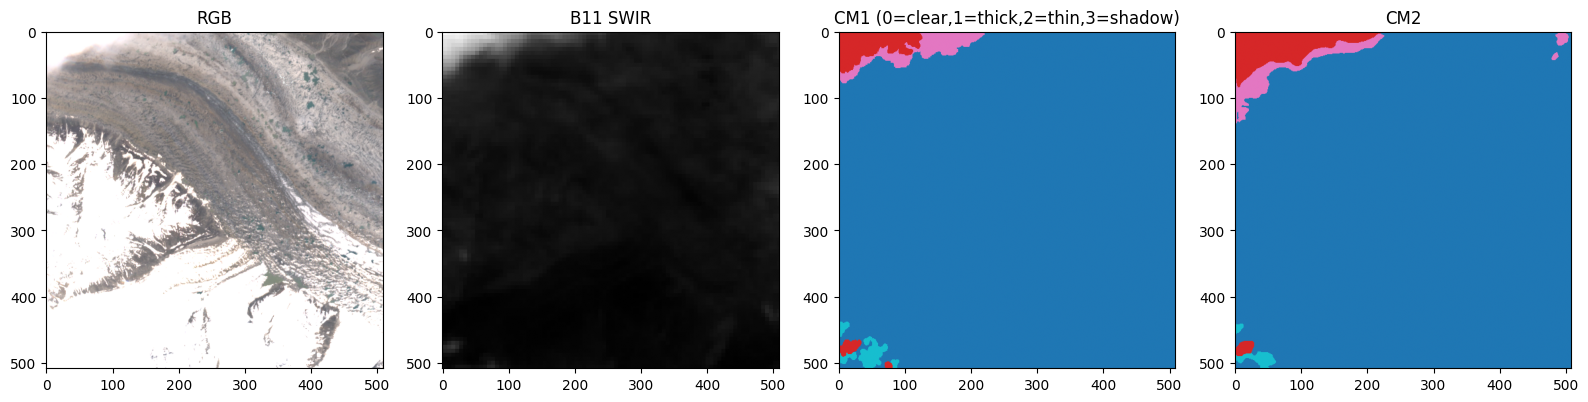

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# RGB (B4, B3, B2)
rgb = data[[3,2,1]].transpose(1,2,0)
rgb = np.clip(rgb / 4000, 0, 1)
axes[0].imshow(rgb)
axes[0].set_title("RGB")

# SWIR (B11 - band index 10)
axes[1].imshow(data[10], cmap='gray')
axes[1].set_title("B11 SWIR")

# CM1 label
axes[2].imshow(data[13], cmap='tab10', vmin=0, vmax=3)
axes[2].set_title("CM1 (0=clear,1=thick,2=thin,3=shadow)")

# CM2 label
axes[3].imshow(data[14], cmap='tab10', vmin=0, vmax=3)
axes[3].set_title("CM2")

plt.tight_layout()
plt.show()

In [4]:
with zipfile.ZipFile(zip_path, 'r') as z:
    tif_files = [f for f in z.namelist() if f.endswith('.tif')]
    
    # Print first 5 filenames and their parts
    for f in tif_files[:5]:
        name = os.path.basename(f)
        parts = name.split('__')
        print(f"Filename: {name}")
        print(f"Parts: {parts}")
        print(f"Num parts: {len(parts)}")
        print()

Filename: high__train__ROI_0360__20190627T053649_20190627T053925_T43SEA.tif
Parts: ['high', 'train', 'ROI_0360', '20190627T053649_20190627T053925_T43SEA.tif']
Num parts: 4

Filename: high__test__ROI_11764__20190118T142039_20190118T143025_T18GYN.tif
Parts: ['high', 'test', 'ROI_11764', '20190118T142039_20190118T143025_T18GYN.tif']
Num parts: 4

Filename: high__train__ROI_10613__20190215T063949_20190215T064934_T40RFT.tif
Parts: ['high', 'train', 'ROI_10613', '20190215T063949_20190215T064934_T40RFT.tif']
Num parts: 4

Filename: high__train__ROI_0719__20191213T075229_20191213T075529_T37QED.tif
Parts: ['high', 'train', 'ROI_0719', '20191213T075229_20191213T075529_T37QED.tif']
Num parts: 4

Filename: high__train__ROI_1319__20200429T075611_20200429T082102_T36MVV.tif
Parts: ['high', 'train', 'ROI_1319', '20200429T075611_20200429T082102_T36MVV.tif']
Num parts: 4



In [5]:
from datetime import datetime
import zipfile
import os

zip_path = r"C:\Users\prash\Downloads\high.zip"
train_count = 0
val_count = 0
test_count = 0
dates = []
tiles = []

with zipfile.ZipFile(zip_path, 'r') as z:
    tif_files = [f for f in z.namelist() if f.endswith('.tif')]
    
    for f in tif_files:
        name = os.path.basename(f)
        parts = name.split('__')
        
        split = parts[1]
        last_part = parts[3]  # '20190627T053649_20190627T053925_T43SEA.tif'
        
        date_str = last_part[:8]  # YYYYMMDD
        tile = last_part.split('_')[-1].replace('.tif', '')  # T43SEA
        
        if split == 'train': train_count += 1
        elif split == 'val': val_count += 1
        elif split == 'test': test_count += 1
        
        dates.append(datetime.strptime(date_str, '%Y%m%d'))
        tiles.append(tile)

print(f"Train: {train_count}")
print(f"Val:   {val_count}")
print(f"Test:  {test_count}")
print(f"Total: {len(tif_files)}")
print(f"\nDate range: {min(dates).date()} to {max(dates).date()}")
print(f"Unique tiles: {len(set(tiles))}")

Train: 267
Val:   23
Test:  52
Total: 342

Date range: 2018-02-07 to 2020-07-30
Unique tiles: 311


In [6]:
from huggingface_hub import list_repo_files

files = list(list_repo_files(
    repo_id="isp-uv-es/CloudSEN12Plus",
    repo_type="dataset"
))

for f in files:
    print(f)

.gitattributes
README.md
cloudsen12.gif
demo/dem_SA_SA5120_E1223N0237.tif
demo/demo.py
demo/demo_p509.tif
demo/models/L2A_EfficientNetUnet.pt
demo/models/UNetMobV2.pt
demo/models/UNetMobV2_V1.pt
demo/models/UNetMobV2_V2.pt
demo/models/resnet10.pt
fixed/high.zip
fixed/scribble.zip
main.json
test/metadata.parquet
test/test_2000_high.mlstac
test/test_509_high.mlstac
test/test_509_scribble.mlstac
train/metadata.parquet
train/train_2000_high.mlstac
train/train_509_high.mlstac
train/train_509_nolabel_chunk1.mlstac
train/train_509_nolabel_chunk2.mlstac
train/train_509_scribble.mlstac
validation/metadata.parquet
validation/validation_2000_high.mlstac
validation/validation_509_high.mlstac
validation/validation_509_scribble.mlstac


In [ ]:

from huggingface_hub import hf_hub_download
import json
import os

os.environ["HF_TOKEN"] = "<your-hf-token>"

dem_path = hf_hub_download(
    repo_id="isp-uv-es/CloudSEN12Plus",
    filename="demo/dem_SA_SA5120_E1223N0237.tif",
    repo_type="dataset",
    local_dir="./data"
)

with rio.open(dem_path) as src:
    print("DEM bands:", src.count)
    print("DEM shape:", src.read().shape)
    print("DEM CRS:", src.crs)
    print("DEM resolution:", src.res)
    dem_data = src.read(1)
    print("Elevation range:", dem_data.min(), "to", dem_data.max(), "meters")

demo/dem_SA_SA5120_E1223N0237.tif:   0%|          | 0.00/92.5M [00:00<?, ?B/s]

In [ ]:
from huggingface_hub import list_repo_files

files = list(list_repo_files(
    repo_id="csaybar/CloudSEN12-high",
    repo_type="dataset"
))

print(f"Total files: {len(files)}")
for f in files:
    print(f)

In [ ]:
from huggingface_hub import get_hf_file_metadata, hf_hub_url

# Check size of a few key files
key_files = [
    "test/EXTRA_elevation.dat",
    "test/L1C_B4.dat",
    "train/EXTRA_elevation.dat",
    "train/L1C_B4.dat"
]

for fname in key_files:
    try:
        url = hf_hub_url(
            repo_id="csaybar/CloudSEN12-high",
            filename=fname,
            repo_type="dataset"
        )
        meta = get_hf_file_metadata(url)
        print(f"{fname}: {meta.size / (1024**3):.2f} GB")
    except Exception as e:
        print(f"{fname}: {e}")

In [ ]:
from huggingface_hub import get_hf_file_metadata, hf_hub_url

key_files = [
    "train/L1C_B4.dat",
    "train/EXTRA_elevation.dat",
    "train/LABEL_manual_hq.dat",
    "train/metadata.csv",
    "val/L1C_B4.dat",
    "test/L1C_B4.dat"
]

total = 0
for fname in key_files:
    url = hf_hub_url(
        repo_id="csaybar/CloudSEN12-high",
        filename=fname,
        repo_type="dataset"
    )
    meta = get_hf_file_metadata(url)
    size_gb = meta.size / (1024**3)
    total += meta.size
    print(f"{fname}: {size_gb:.3f} GB")

print(f"\nEstimated total for all 13 L1C bands + elevation + label: ~{total * 15 / (1024**3):.1f} GB")

In [ ]:
from huggingface_hub import hf_hub_download
import json
os.environ["HF_TOKEN"] = "<your-hf-token>"

# Download the mlstac index file - it's just metadata, very small
path = hf_hub_download(
    repo_id="isp-uv-es/CloudSEN12Plus",
    filename="train/train_509_high.mlstac",
    repo_type="dataset",
    local_dir="./data"
)

# Try reading it as JSON
with open(path, 'r') as f:
    content = f.read()
    print(content[:2000])  # First 2000 characters

In [2]:
import numpy as np

# memmap the file - shape is (8490, 512, 512), dtype is uint16 for L1C bands
band = np.memmap(r"C:\Users\prash\toposegnet\data\high_509\Train\L1C_B1.dat", dtype='uint16', mode='r', shape=(8490, 512, 512))

print("Shape:", band.shape)
print("Dtype:", band.dtype)
print("Min:", band.min())
print("Max:", band.max())
print("Sample patch 0 stats - min:", band[0].min(), "max:", band[0].max(), "mean:", band[0].mean())

Shape: (8490, 512, 512)
Dtype: uint16
Min: 0
Max: 18641
Sample patch 0 stats - min: 0 max: 9082 mean: 4560.328918457031
